In [ ]:
!pip install ultralytics -q

import os
import zipfile
import glob
import pandas as pd
import random
from ultralytics import YOLO
import shutil

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 20.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
import random
import numpy as np
import torch
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

label_path = "/content/drive/MyDrive/all_data/labels"

total_images = 0
total_objects = 0

for file in os.listdir(label_path):
    if file.endswith(".txt"):
        total_images += 1  # 1 file = 1 citra

        with open(os.path.join(label_path, file), "r") as f:
            lines = f.readlines()

            # ambil hanya baris valid YOLO (5 angka)
            valid = [l for l in lines if len(l.strip().split()) == 5]
            total_objects += len(valid)

print("Total citra:", total_images)
print("Total objek (bounding box):", total_objects)

Total citra: 2367
Total objek (bounding box): 3835


**====🚀SKENARIO 1 =======**

**===========================**
---



In [ ]:
ZIP_PATH = "/content/drive/MyDrive/skenario_1.zip"
EXTRACT_PATH = "/content/data_skenario1"

if os.path.exists(EXTRACT_PATH):
    shutil.rmtree(EXTRACT_PATH)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset Skenario 1 siap")

Dataset Skenario 1 siap


In [ ]:
import yaml

yaml_path = "/content/data_skenario1/skenario_1/skenario_1/datasetSKENARIO1.yaml"

with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

# FIX PATH
data['train'] = "/content/data_skenario1/skenario_1/skenario_1/train/images"
data['val']   = "/content/data_skenario1/skenario_1/skenario_1/valid/images"
data['test']  = "/content/data_skenario1/skenario_1/skenario_1/test/images"

with open(yaml_path, 'w') as f:
    yaml.dump(data, f)

print("✅ YAML FIXED")

✅ YAML FIXED


In [ ]:
DATA_YAML = "/content/data_skenario1/skenario_1/skenario_1/datasetSKENARIO1.yaml"

assert os.path.exists(DATA_YAML), "dataset.yaml tidak ditemukan!"
print("Path OK:", DATA_YAML)

Path OK: /content/data_skenario1/skenario_1/skenario_1/datasetSKENARIO1.yaml


TRAINING V11S

In [ ]:
MODEL_NAME = "yolo11s.pt"
RUN_NAME = "Skenario1_YOLO11s"

results_v11 = []

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

for run in range(10):
    seed = run
    set_seed(seed)

    print("\n" + "="*50)
    print(f" YOLOv11s RUN {run+1}")
    print("="*50)

    model = YOLO(MODEL_NAME)

    model.train(
        data="/content/data_skenario1/skenario_1/skenario_1/datasetSKENARIO1.yaml",
        epochs=50,
        imgsz=640,
        batch=16,
        amp=True,
        plots=True,
        verbose=True,
        seed=seed,
        name=f"{RUN_NAME}_run{run+1}"
    )

    metrics = model.val(data="/content/data_skenario1/skenario_1/skenario_1/datasetSKENARIO1.yaml")

    P = metrics.box.p.mean()
    R = metrics.box.r.mean()
    mAP50 = metrics.box.map50
    mAP5095 = metrics.box.map

    F1 = 2 * (P * R) / (P + R + 1e-6)

    cm = metrics.confusion_matrix.matrix
    if cm.shape[0] > 2:
        cm = cm[:2, :2]

    TP = cm[1,1]
    TN = cm[0,0]
    FP = cm[0,1]
    FN = cm[1,0]

    ACC = (TP + TN) / (TP + TN + FP + FN + 1e-6)

    print("\n🎖️ HASIL KLASIFIKASI")
    print(f"TP:{TP} TN:{TN} FP:{FP} FN:{FN}")
    print(f"Accuracy: {ACC*100:.2f}%")

    results_v11.append({
        "skenario": "Skenario 1",
        "model": "YOLOv11s",
        "run": run+1,
        "precision": P,
        "recall": R,
        "mAP50": mAP50,
        "mAP50-95": mAP5095,
        "accuracy": ACC,
        "f1_score": F1
    })

df_v11 = pd.DataFrame(results_v11)

csv_path_v11 = "/content/drive/MyDrive/SKRIPSI_YOLO/Skenario1_YOLO11s.csv"
df_v11.to_csv(csv_path_v11, index=False)

print("CSV YOLOv11s:", csv_path_v11)
display(df_v11)


🚀 YOLOv11s RUN 1
Ultralytics 8.4.45 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_skenario1/skenario_1/skenario_1/datasetSKENARIO1.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Skenario1_YOLO11s_run1-2, nbs=64, nms=False, o

,skenario,model,run,precision,recall,mAP50,mAP50-95,accuracy,f1_score
0,Skenario 1,YOLOv11s,1,0.803474,0.784766,0.824850,0.372814,0.963035,0.794009
1,Skenario 1,YOLOv11s,2,0.796577,0.794824,0.828273,0.364940,0.962451,0.795699
2,Skenario 1,YOLOv11s,3,0.833190,0.798857,0.833728,0.367856,0.970817,0.815662
3,Skenario 1,YOLOv11s,4,0.810019,0.791255,0.814596,0.363178,0.974308,0.800526
4,Skenario 1,YOLOv11s,5,0.793429,0.803981,0.833184,0.368846,0.964775,0.798670
5,Skenario 1,YOLOv11s,6,0.778795,0.833650,0.828375,0.374797,0.976654,0.805289
6,Skenario 1,YOLOv11s,7,0.810737,0.782715,0.826222,0.364763,0.970060,0.796479
7,Skenario 1,YOLOv11s,8,0.784261,0.781133,0.822584,0.362954,0.970530,0.782693
8,Skenario 1,YOLOv11s,9,0.815935,0.762523,0.819507,0.363406,0.962598,0.788325
9,Skenario 1,YOLOv11s,10,0.771030,0.809567,0.834431,0.368732,0.958824,0.789829


In [ ]:
print("\n📊 REKAP EVALUASI 10 KALI RUN (SKENARIO 1 - YOLOv11s)")
print("="*60)

mean_v11 = df_v11.mean(numeric_only=True)
print("\n📈 NILAI RATA-RATA:")
print(mean_v11)

best_idx_v11 = df_v11["mAP50"].idxmax()
best_v11 = df_v11.loc[best_idx_v11]

print("\n🏆 MODEL TERBAIK (YOLOv11s):")
print(f"RUN KE-{int(best_v11['run'])}")
print(f"mAP50: {best_v11['mAP50']:.4f}")
print(f"F1   : {best_v11['f1_score']:.4f}")


📊 REKAP EVALUASI 10 KALI RUN (SKENARIO 1 - YOLOv11s)

📈 NILAI RATA-RATA:
run          5.500000
precision    0.799745
recall       0.794327
mAP50        0.826575
mAP50-95     0.367229
accuracy     0.967405
f1_score     0.796718
dtype: float64

🏆 MODEL TERBAIK (YOLOv11s):
RUN KE-10
mAP50: 0.8344
F1   : 0.7898


ZIP V11 SKENARIO1

In [ ]:
import shutil
from google.colab import files

BASE_DIR = "/content/runs/detect"
ZIP_PATH = "/content/Skenario1_YOLO11s.zip"

temp_dir = "/content/temp_v11"

# reset folder temp
if os.path.exists(temp_dir):
    shutil.rmtree(temp_dir)

os.makedirs(temp_dir)

# copy semua run v11
for folder in os.listdir(BASE_DIR):
    if "Skenario1_YOLO11s" in folder:
        shutil.copytree(
            os.path.join(BASE_DIR, folder),
            os.path.join(temp_dir, folder)
        )

# zip
shutil.make_archive(ZIP_PATH.replace(".zip",""), 'zip', temp_dir)

files.download(ZIP_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

V12S SKENARIO 1

In [ ]:
MODEL_NAME = "yolo12s.pt"
RUN_NAME = "Skenario1_YOLO12s"

results_v12 = []

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

for run in range(10):
    seed = run
    set_seed(seed)

    print("\n" + "="*50)
    print(f"🚀 YOLOv12s RUN {run+1}")
    print("="*50)

    model = YOLO(MODEL_NAME)

    model.train(
        data="/content/data_skenario1/skenario_1/skenario_1/datasetSKENARIO1.yaml",
        epochs=50,
        imgsz=640,
        batch=16,
        amp=True,
        plots=True,
        verbose=True,
        seed=seed,
        name=f"{RUN_NAME}_run{run+1}"
    )

    metrics = model.val()

    P = metrics.box.p.mean()
    R = metrics.box.r.mean()
    mAP50 = metrics.box.map50
    mAP5095 = metrics.box.map

    F1 = 2 * (P * R) / (P + R + 1e-6)

    cm = metrics.confusion_matrix.matrix
    if cm.shape[0] > 2:
        cm = cm[:2, :2]

    TP = cm[1,1]
    TN = cm[0,0]
    FP = cm[0,1]
    FN = cm[1,0]

    ACC = (TP + TN) / (TP + TN + FP + FN + 1e-6)

    results_v12.append({
        "skenario": "Skenario 1",
        "model": "YOLOv12s",
        "run": run+1,
        "precision": P,
        "recall": R,
        "mAP50": mAP50,
        "mAP50-95": mAP5095,
        "accuracy": ACC,
        "f1_score": F1
    })

df_v12 = pd.DataFrame(results_v12)

csv_path_v12 = "/content/drive/MyDrive/SKRIPSI_YOLO/Skenario1_YOLO12s.csv"
df_v12.to_csv(csv_path_v12, index=False)

print("CSV YOLOv12s:", csv_path_v12)
display(df_v12)


🚀 YOLOv12s RUN 1
Ultralytics 8.4.45 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_skenario1/skenario_1/skenario_1/datasetSKENARIO1.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Skenario1_YOLO12s_run1, nbs=64, nms=False, ops

,skenario,model,run,precision,recall,mAP50,mAP50-95,accuracy,f1_score
0,Skenario 1,YOLOv12s,1,0.804946,0.784668,0.825731,0.362411,0.968750,0.794677
1,Skenario 1,YOLOv12s,2,0.810592,0.781527,0.842999,0.369829,0.972603,0.795794
2,Skenario 1,YOLOv12s,3,0.799890,0.815841,0.843808,0.366031,0.976424,0.807786
3,Skenario 1,YOLOv12s,4,0.812547,0.794819,0.832331,0.369528,0.970703,0.803585
4,Skenario 1,YOLOv12s,5,0.825668,0.804276,0.846485,0.370402,0.964706,0.814831
5,Skenario 1,YOLOv12s,6,0.801326,0.773320,0.819960,0.371576,0.966469,0.787074
6,Skenario 1,YOLOv12s,7,0.813135,0.766018,0.827353,0.364294,0.966270,0.788873
7,Skenario 1,YOLOv12s,8,0.786418,0.799344,0.832463,0.367873,0.965318,0.792828
8,Skenario 1,YOLOv12s,9,0.829631,0.803789,0.861768,0.370811,0.970930,0.816505
9,Skenario 1,YOLOv12s,10,0.806766,0.821018,0.846195,0.370245,0.976562,0.813829


In [ ]:
print("\n📊 REKAP EVALUASI 10 KALI RUN (SKENARIO 1 - YOLOv12s)")
print("="*60)

mean_v12 = df_v12.mean(numeric_only=True)
print("\n📈 NILAI RATA-RATA:")
print(mean_v12)

best_idx_v12 = df_v12["mAP50"].idxmax()
best_v12 = df_v12.loc[best_idx_v12]

print("\n🏆 MODEL TERBAIK (YOLOv12s):")
print(f"RUN KE-{int(best_v12['run'])}")
print(f"mAP50: {best_v12['mAP50']:.4f}")
print(f"F1   : {best_v12['f1_score']:.4f}")


📊 REKAP EVALUASI 10 KALI RUN (SKENARIO 1 - YOLOv12s)

📈 NILAI RATA-RATA:
run          5.500000
precision    0.809092
recall       0.794462
mAP50        0.837909
mAP50-95     0.368300
accuracy     0.969874
f1_score     0.801578
dtype: float64

🏆 MODEL TERBAIK (YOLOv12s):
RUN KE-9
mAP50: 0.8618
F1   : 0.8165


ZIP V12 SKENARIO1

In [ ]:
import os
import shutil
from google.colab import files

BASE_DIR = "/content/runs/detect"
ZIP_PATH = "/content/Skenario1_YOLO12s.zip"
temp_dir = "/content/temp_v12"

# Hapus temp lama
if os.path.exists(temp_dir):
    shutil.rmtree(temp_dir)

os.makedirs(temp_dir)

# Copy semua hasil run YOLO12s Skenario 1
for folder in os.listdir(BASE_DIR):
    if "Skenario1_YOLO12s" in folder:
        shutil.copytree(
            os.path.join(BASE_DIR, folder),
            os.path.join(temp_dir, folder)
        )

# Buat ZIP
shutil.make_archive(ZIP_PATH.replace(".zip",""), 'zip', temp_dir)

# Download
files.download(ZIP_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PERBANDINGAN

In [ ]:
import pandas as pd

df_v11 = pd.read_csv("/content/drive/MyDrive/SKRIPSI_YOLO/Skenario1_YOLO11s.csv")
df_v12 = pd.read_csv("/content/drive/MyDrive/SKRIPSI_YOLO/Skenario1_YOLO12s.csv")

In [ ]:
# HITUNG RATA-RATA
mean_v11 = df_v11.mean(numeric_only=True)
mean_v12 = df_v12.mean(numeric_only=True)

# TAMPILKAN
print("\n📊 PERBANDINGAN MODEL (SKENARIO 1)")
print("="*60)

print("\nYOLOv11s:")
print(mean_v11)

print("\nYOLOv12s:")
print(mean_v12)


📊 PERBANDINGAN MODEL (SKENARIO 1)

YOLOv11s:
run          5.500000
precision    0.799745
recall       0.794327
mAP50        0.826575
mAP50-95     0.367229
accuracy     0.967405
f1_score     0.796718
dtype: float64

YOLOv12s:
run          5.500000
precision    0.809092
recall       0.794462
mAP50        0.837909
mAP50-95     0.368300
accuracy     0.969874
f1_score     0.801578
dtype: float64


MODEL TERBAIK SKENARIO 1

In [ ]:
if mean_v11["mAP50"] > mean_v12["mAP50"]:
    print("\n🏆 MODEL TERBAIK SKENARIO 1: YOLOv11s")
else:
    print("\n🏆 MODEL TERBAIK SKENARIO 1: YOLOv12s")


🏆 MODEL TERBAIK SKENARIO 1: YOLOv12s


**========== 🚀 SKENARIO 2 ==========**

**=====================================**

In [ ]:
ZIP_PATH = "/content/drive/MyDrive/skenario_2.zip"
EXTRACT_PATH = "/content/data_skenario2"

if os.path.exists(EXTRACT_PATH):
    shutil.rmtree(EXTRACT_PATH)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset Skenario 2 siap")

Dataset Skenario 2 siap


In [ ]:
import yaml

yaml_path = "/content/data_skenario2/skenario_2/skenario_2/datasetSKENARIO2.yaml"

with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

data['train'] = "/content/data_skenario2/skenario_2/skenario_2/train/images"
data['val']   = "/content/data_skenario2/skenario_2/skenario_2/valid/images"
data['test']  = "/content/data_skenario2/skenario_2/skenario_2/test/images"

with open(yaml_path, 'w') as f:
    yaml.dump(data, f)

print("✅ YAML SKENARIO 2 FIXED")

✅ YAML SKENARIO 2 FIXED


In [ ]:
DATA_YAML = "/content/data_skenario2/skenario_2/skenario_2/datasetSKENARIO2.yaml"

assert os.path.exists(DATA_YAML), "dataset.yaml tidak ditemukan!"
print("Path OK:", DATA_YAML)

Path OK: /content/data_skenario2/skenario_2/skenario_2/datasetSKENARIO2.yaml


TRAINING V11 SKENARIO 2

In [ ]:
MODEL_NAME = "yolo11s.pt"
RUN_NAME = "Skenario2_YOLO11s"

results_v11 = []

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

for run in range(10):
    seed = run
    set_seed(seed)

    print(f"\n🚀 YOLOv11s RUN {run+1}")

    model = YOLO(MODEL_NAME)

    model.train(
        data="/content/data_skenario2/skenario_2/skenario_2/datasetSKENARIO2.yaml",
        epochs=50,
        imgsz=640,
        batch=16,
        amp=True,
        plots=True,
        verbose=True,
        seed=seed,
        name=f"{RUN_NAME}_run{run+1}"
    )

    metrics = model.val()

    P = metrics.box.p.mean()
    R = metrics.box.r.mean()
    mAP50 = metrics.box.map50
    mAP5095 = metrics.box.map

    F1 = 2 * (P * R) / (P + R + 1e-6)

    cm = metrics.confusion_matrix.matrix
    if cm.shape[0] > 2:
        cm = cm[:2, :2]

    TP, TN, FP, FN = cm[1,1], cm[0,0], cm[0,1], cm[1,0]
    ACC = (TP + TN) / (TP + TN + FP + FN + 1e-6)

    print(f"mAP50: {mAP50:.4f} | F1: {F1:.4f}")

    results_v11.append({
        "run": run+1,
        "precision": P,
        "recall": R,
        "mAP50": mAP50,
        "mAP50-95": mAP5095,
        "accuracy": ACC,
        "f1_score": F1
    })

df_v11 = pd.DataFrame(results_v11)
df_v11.to_csv("/content/drive/MyDrive/SKRIPSI_YOLO/Skenario2_YOLO11s.csv", index=False)

display(df_v11)


🚀 YOLOv11s RUN 1
Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_skenario2/skenario_2/skenario_2/datasetSKENARIO2.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Skenario2_YOLO11s_run1-4, nbs=64, nms=False, o

,run,precision,recall,mAP50,mAP50-95,accuracy,f1_score
0,1,0.812344,0.788486,0.838526,0.376959,0.965217,0.800237
1,2,0.825445,0.780268,0.830851,0.369358,0.967742,0.802220
2,3,0.841294,0.796255,0.842895,0.373634,0.971098,0.818155
3,4,0.823228,0.794820,0.831962,0.372004,0.972018,0.808774
4,5,0.821604,0.808211,0.841574,0.373835,0.969388,0.814852
5,6,0.823010,0.806765,0.846138,0.383173,0.965368,0.814806
6,7,0.814963,0.800776,0.835749,0.370622,0.970588,0.807807
7,8,0.811568,0.781499,0.840248,0.369711,0.973761,0.796249
8,9,0.819334,0.776491,0.834787,0.370858,0.968345,0.797337
9,10,0.833993,0.771816,0.832502,0.375774,0.965015,0.801701


In [ ]:
print("\n📊 REKAP SKENARIO 2 - YOLOv11s")
print(df_v11.mean(numeric_only=True))

best = df_v11.loc[df_v11["mAP50"].idxmax()]
print("\nBEST RUN:", best["run"])


📊 REKAP SKENARIO 2 - YOLOv11s
run          5.500000
precision    0.822678
recall       0.790539
mAP50        0.837523
mAP50-95     0.373593
accuracy     0.968854
f1_score     0.806214
dtype: float64

BEST RUN: 6.0


ZIP V11 SKENARIO 2

In [ ]:
import os, shutil
from google.colab import files

BASE_DIR = "/content/runs/detect"
temp_dir = "/content/temp_S2_v11"
zip_path = "/content/Skenario2_YOLO11s.zip"

if os.path.exists(temp_dir):
    shutil.rmtree(temp_dir)
os.makedirs(temp_dir)

for folder in os.listdir(BASE_DIR):
    if "Skenario2_YOLO11s" in folder:
        shutil.copytree(
            os.path.join(BASE_DIR, folder),
            os.path.join(temp_dir, folder)
        )

shutil.make_archive(zip_path.replace(".zip",""), 'zip', temp_dir)

print("✅ ZIP siap:", zip_path)
files.download(zip_path)

✅ ZIP siap: /content/Skenario2_YOLO11s.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

TRAINING V12 SKENARIO 2

In [ ]:
MODEL_NAME = "yolo12s.pt"
RUN_NAME = "Skenario2_YOLO12s"

results_v12 = []

for run in range(10):
    seed = run
    set_seed(seed)

    print(f"\n🚀 YOLOv12s RUN {run+1}")

    model = YOLO(MODEL_NAME)

    model.train(
        data="/content/data_skenario2/skenario_2/skenario_2/datasetSKENARIO2.yaml",
        epochs=50,
        imgsz=640,
        batch=16,
        amp=True,
        plots=True,
        verbose=True,
        seed=seed,
        name=f"{RUN_NAME}_run{run+1}"
    )

    metrics = model.val()

    P = metrics.box.p.mean()
    R = metrics.box.r.mean()
    mAP50 = metrics.box.map50
    mAP5095 = metrics.box.map

    F1 = 2 * (P * R) / (P + R + 1e-6)

    cm = metrics.confusion_matrix.matrix
    if cm.shape[0] > 2:
        cm = cm[:2, :2]

    TP, TN, FP, FN = cm[1,1], cm[0,0], cm[0,1], cm[1,0]
    ACC = (TP + TN) / (TP + TN + FP + FN + 1e-6)

    results_v12.append({
        "run": run+1,
        "precision": P,
        "recall": R,
        "mAP50": mAP50,
        "mAP50-95": mAP5095,
        "accuracy": ACC,
        "f1_score": F1
    })

df_v12 = pd.DataFrame(results_v12)
df_v12.to_csv("/content/drive/MyDrive/SKRIPSI_YOLO/Skenario2_YOLO12s.csv", index=False)

display(df_v12)


🚀 YOLOv12s RUN 1
Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_skenario2/skenario_2/skenario_2/datasetSKENARIO2.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Skenario2_YOLO12s_run1-2, nbs=64, nms=False, o

,run,precision,recall,mAP50,mAP50-95,accuracy,f1_score
0,1,0.826820,0.786268,0.843585,0.372066,0.969653,0.806034
1,2,0.823653,0.784854,0.850523,0.374135,0.973723,0.803785
2,3,0.819920,0.799135,0.848042,0.374783,0.978038,0.809393
3,4,0.836349,0.780196,0.839222,0.372521,0.970760,0.807297
4,5,0.844576,0.785971,0.851072,0.374619,0.970501,0.814219
5,6,0.806198,0.799878,0.843058,0.382135,0.970717,0.803025
6,7,0.820507,0.771436,0.838414,0.369911,0.970458,0.795215
7,8,0.817148,0.787089,0.844267,0.376163,0.969871,0.801836
8,9,0.838334,0.794097,0.857577,0.374208,0.965368,0.815616
9,10,0.845431,0.794956,0.851345,0.373100,0.975219,0.819416


In [ ]:
print("\n📊 REKAP SKENARIO 2 - YOLOv12s")
print(df_v12.mean(numeric_only=True))

best = df_v12.loc[df_v12["mAP50"].idxmax()]
print("\nBEST RUN:", best["run"])


📊 REKAP SKENARIO 2 - YOLOv12s
run          5.500000
precision    0.827893
recall       0.788388
mAP50        0.846711
mAP50-95     0.374364
accuracy     0.971431
f1_score     0.807584
dtype: float64

BEST RUN: 9.0


ZIP V12 SKENARIO 2

In [ ]:
temp_dir = "/content/temp_S2_v12"
zip_path = "/content/Skenario2_YOLO12s.zip"

if os.path.exists(temp_dir):
    shutil.rmtree(temp_dir)
os.makedirs(temp_dir)

for folder in os.listdir(BASE_DIR):
    if "Skenario2_YOLO12s" in folder:
        shutil.copytree(
            os.path.join(BASE_DIR, folder),
            os.path.join(temp_dir, folder)
        )

shutil.make_archive(zip_path.replace(".zip",""), 'zip', temp_dir)

print("✅ ZIP siap:", zip_path)
files.download(zip_path)

✅ ZIP siap: /content/Skenario2_YOLO12s.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**========== 🚀 SKENARIO 3 ==========**

**=====================================**

In [ ]:
ZIP_PATH = "/content/drive/MyDrive/skenario_3.zip"
EXTRACT_PATH = "/content/data_skenario3"

if os.path.exists(EXTRACT_PATH):
    shutil.rmtree(EXTRACT_PATH)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset Skenario 3 siap")

Dataset Skenario 3 siap


In [ ]:
import yaml

yaml_path = "/content/data_skenario3/skenario_3/skenario_3/datasetSKENARIO3.yaml"

with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

data['train'] = "/content/data_skenario3/skenario_3/skenario_3/train/images"
data['val']   = "/content/data_skenario3/skenario_3/skenario_3/valid/images"
data['test']  = "/content/data_skenario3/skenario_3/skenario_3/test/images"

with open(yaml_path, 'w') as f:
    yaml.dump(data, f)

print("✅ YAML SKENARIO 3 FIXED")

✅ YAML SKENARIO 3 FIXED


In [ ]:
DATA_YAML = "/content/data_skenario3/skenario_3/skenario_3/datasetSKENARIO3.yaml"

assert os.path.exists(DATA_YAML), "dataset.yaml tidak ditemukan!"
print("Path OK:", DATA_YAML)

Path OK: /content/data_skenario3/skenario_3/skenario_3/datasetSKENARIO3.yaml


TRAINING V11 SKENARIO 3

In [ ]:
MODEL_NAME = "yolo11s.pt"
RUN_NAME = "Skenario3_YOLO11s"

results_v11 = []

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

for run in range(10):
    seed = run
    set_seed(seed)

    print("\n" + "="*50)
    print(f"🚀 YOLOv11s RUN {run+1}")
    print("="*50)

    model = YOLO(MODEL_NAME)

    model.train(
        data="/content/data_skenario3/skenario_3/skenario_3/datasetSKENARIO3.yaml",
        epochs=50,
        imgsz=640,
        batch=16,
        amp=True,
        plots=True,
        verbose=True,
        seed=seed,
        name=f"{RUN_NAME}_run{run+1}"
    )

    metrics = model.val()

    P = metrics.box.p.mean()
    R = metrics.box.r.mean()
    mAP50 = metrics.box.map50
    mAP5095 = metrics.box.map

    F1 = 2 * (P * R) / (P + R + 1e-6)

    cm = metrics.confusion_matrix.matrix
    if cm.shape[0] > 2:
        cm = cm[:2, :2]

    TP = cm[1,1]
    TN = cm[0,0]
    FP = cm[0,1]
    FN = cm[1,0]

    ACC = (TP + TN) / (TP + TN + FP + FN + 1e-6)

    print(f"mAP50: {mAP50:.4f} | F1: {F1:.4f}")

    results_v11.append({
        "run": run+1,
        "precision": P,
        "recall": R,
        "mAP50": mAP50,
        "mAP50-95": mAP5095,
        "accuracy": ACC,
        "f1_score": F1
    })

df_v11 = pd.DataFrame(results_v11)
df_v11.to_csv("/content/drive/MyDrive/SKRIPSI_YOLO/Skenario3_YOLO11s.csv", index=False)

display(df_v11)

In [ ]:
print("\n📊 REKAP SKENARIO 3 - YOLOv11s")
print("="*60)

mean_v11 = df_v11.mean(numeric_only=True)
print(mean_v11)

best = df_v11.loc[df_v11["mAP50"].idxmax()]

print("\n🏆 BEST RUN YOLOv11s:")
print(f"Run  : {int(best['run'])}")
print(f"mAP50: {best['mAP50']:.4f}")
print(f"F1   : {best['f1_score']:.4f}")


📊 REKAP SKENARIO 3 - YOLOv11s
run          5.500000
precision    0.830826
recall       0.829999
mAP50        0.884185
mAP50-95     0.407976
accuracy     0.974525
f1_score     0.830371
dtype: float64

🏆 BEST RUN YOLOv11s:
Run  : 8
mAP50: 0.8986
F1   : 0.8486


ZIP V11 SKENARIO 3

In [ ]:
import os
import shutil
from google.colab import files  # WAJIB

BASE_DIR = "/content/runs/detect"

temp_dir = "/content/temp_S3_v11"
zip_path = "/content/Skenario3_YOLO11s.zip"

if os.path.exists(temp_dir):
    shutil.rmtree(temp_dir)
os.makedirs(temp_dir)

for folder in os.listdir(BASE_DIR):
    if "Skenario3_YOLO11s" in folder:
        shutil.copytree(
            os.path.join(BASE_DIR, folder),
            os.path.join(temp_dir, folder)
        )

shutil.make_archive(zip_path.replace(".zip",""), 'zip', temp_dir)

print("✅ ZIP siap:", zip_path)

files.download(zip_path)

✅ ZIP siap: /content/Skenario3_YOLO11s.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

TRAINING V12 SKENARIO 3

In [ ]:
import random
import numpy as np
import torch
import pandas as pd
from ultralytics import YOLO

In [ ]:
MODEL_NAME = "yolo12s.pt"
RUN_NAME = "Skenario3_YOLO12s"

results_v12 = []

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

for run in range(10):
    seed = run
    set_seed(seed)

    print("\n" + "="*50)
    print(f"🚀 YOLOv12s RUN {run+1}")
    print("="*50)

    model = YOLO(MODEL_NAME)

    model.train(
        data="/content/data_skenario3/skenario_3/skenario_3/datasetSKENARIO3.yaml",
        epochs=50,
        imgsz=640,
        batch=16,
        amp=True,
        plots=True,
        verbose=True,
        seed=seed,
        name=f"{RUN_NAME}_run{run+1}"
    )

    metrics = model.val()

    P = metrics.box.p.mean()
    R = metrics.box.r.mean()
    mAP50 = metrics.box.map50
    mAP5095 = metrics.box.map

    F1 = 2 * (P * R) / (P + R + 1e-6)

    cm = metrics.confusion_matrix.matrix
    if cm.shape[0] > 2:
        cm = cm[:2, :2]

    TP = cm[1,1]
    TN = cm[0,0]
    FP = cm[0,1]
    FN = cm[1,0]

    ACC = (TP + TN) / (TP + TN + FP + FN + 1e-6)

    results_v12.append({
        "run": run+1,
        "precision": P,
        "recall": R,
        "mAP50": mAP50,
        "mAP50-95": mAP5095,
        "accuracy": ACC,
        "f1_score": F1
    })

df_v12 = pd.DataFrame(results_v12)
df_v12.to_csv("/content/drive/MyDrive/SKRIPSI_YOLO/Skenario3_YOLO12s.csv", index=False)

display(df_v12)


🚀 YOLOv12s RUN 1
Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_skenario3/skenario_3/skenario_3/datasetSKENARIO3.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Skenario3_YOLO12s_run1, nbs=64, nms=False, ops

,run,precision,recall,mAP50,mAP50-95,accuracy,f1_score
0,1,0.866433,0.815556,0.884974,0.401943,0.970930,0.840225
1,2,0.833426,0.831987,0.877510,0.403969,0.974138,0.832706
2,3,0.862594,0.832601,0.897152,0.406244,0.979710,0.847332
3,4,0.856805,0.847086,0.897074,0.408563,0.985507,0.851918
4,5,0.861044,0.859081,0.897222,0.399839,0.974212,0.860061
5,6,0.841441,0.840639,0.892669,0.411066,0.977011,0.841039
6,7,0.863664,0.847349,0.898277,0.399164,0.985591,0.855428
7,8,0.821225,0.803537,0.864078,0.386190,0.976540,0.812284
8,9,0.832958,0.818716,0.878746,0.403270,0.976879,0.825775
9,10,0.830032,0.826591,0.888303,0.401420,0.971510,0.828307


In [ ]:
print("\n📊 REKAP SKENARIO 3 - YOLOv12s")
print("="*60)

mean_v12 = df_v12.mean(numeric_only=True)
print(mean_v12)

best = df_v12.loc[df_v12["mAP50"].idxmax()]

print("\n🏆 BEST RUN YOLOv12s:")
print(f"Run  : {int(best['run'])}")
print(f"mAP50: {best['mAP50']:.4f}")
print(f"F1   : {best['f1_score']:.4f}")


📊 REKAP SKENARIO 3 - YOLOv12s
run          5.500000
precision    0.846962
recall       0.832314
mAP50        0.887600
mAP50-95     0.402167
accuracy     0.977203
f1_score     0.839507
dtype: float64

🏆 BEST RUN YOLOv12s:
Run  : 7
mAP50: 0.8983
F1   : 0.8554


ZIP V12 SKENARIO 3

In [ ]:
import os
import shutil
from google.colab import files  # WAJIB

BASE_DIR = "/content/runs/detect"

temp_dir = "/content/temp_S3_v12"
zip_path = "/content/Skenario3_YOLO12s.zip"

if os.path.exists(temp_dir):
    shutil.rmtree(temp_dir)
os.makedirs(temp_dir)

for folder in os.listdir(BASE_DIR):
    if "Skenario3_YOLO12s" in folder:
        shutil.copytree(
            os.path.join(BASE_DIR, folder),
            os.path.join(temp_dir, folder)
        )

shutil.make_archive(zip_path.replace(".zip",""), 'zip', temp_dir)

print("✅ ZIP siap:", zip_path)
files.download(zip_path)

✅ ZIP siap: /content/Skenario3_YOLO12s.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**PERBANDINGAN**

In [ ]:
mean_v11_s1 = {
    "precision": 0.7997,
    "recall": 0.7943,
    "mAP50": 0.8266,
    "mAP50-95": 0.3672,
    "accuracy": 0.9674,
    "f1_score": 0.7967
}

mean_v12_s1 = {
    "precision": 0.8091,
    "recall": 0.7945,
    "mAP50": 0.8379,
    "mAP50-95": 0.3683,
    "accuracy": 0.9699,
    "f1_score": 0.8016
}

mean_v11_s2 = {
    "precision": 0.8157,
    "recall": 0.7905,
    "mAP50": 0.8397,
    "mAP50-95": 0.3741,
    "accuracy": 0.9698,
    "f1_score": 0.8028
}

mean_v12_s2 = {
    "precision": 0.8279,
    "recall": 0.7884,
    "mAP50": 0.8467,
    "mAP50-95": 0.3744,
    "accuracy": 0.9714,
    "f1_score": 0.8076
}

mean_v11_s3 = {
    "precision": 0.8308,
    "recall": 0.8300,
    "mAP50": 0.8842,
    "mAP50-95": 0.4080,
    "accuracy": 0.9745,
    "f1_score": 0.8304
}

mean_v12_s3 = {
    "precision": 0.8470,
    "recall": 0.8323,
    "mAP50": 0.8876,
    "mAP50-95": 0.4022,
    "accuracy": 0.9772,
    "f1_score": 0.8395
}

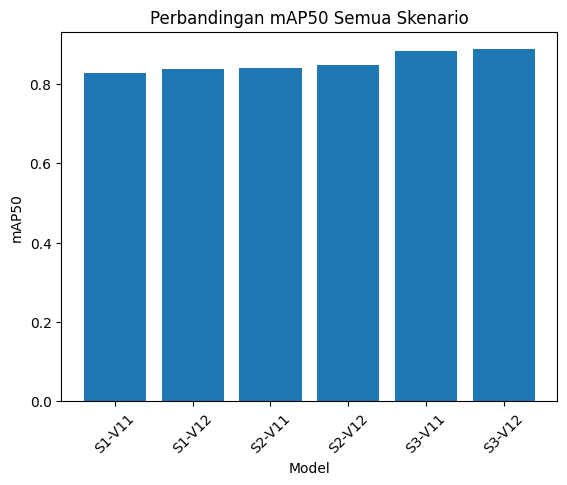

In [ ]:
import matplotlib.pyplot as plt

labels = ["S1-V11", "S1-V12", "S2-V11", "S2-V12", "S3-V11", "S3-V12"]

map50_values = [
    mean_v11_s1["mAP50"],
    mean_v12_s1["mAP50"],
    mean_v11_s2["mAP50"],
    mean_v12_s2["mAP50"],
    mean_v11_s3["mAP50"],
    mean_v12_s3["mAP50"]
]

plt.figure()
plt.bar(labels, map50_values)
plt.title("Perbandingan mAP50 Semua Skenario")
plt.xlabel("Model")
plt.ylabel("mAP50")
plt.xticks(rotation=45)
plt.show()

**TRAINING UKURAN CITRA**

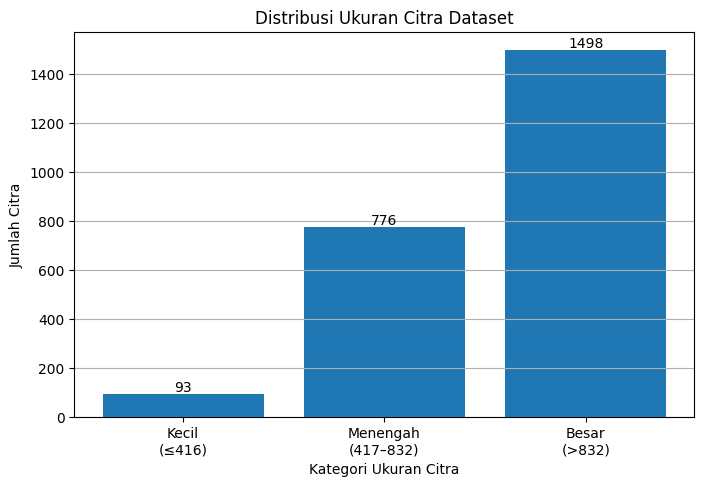

Total gambar: 2367

Distribusi ukuran:
Kecil     : 93
Menengah  : 776
Besar     : 1498


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# LOAD CSV
# =========================
df = pd.read_csv("/content/drive/MyDrive/CODINGAN SKRIPSI/analisis_ukuran_dataset.csv")

# =========================
# UKURAN REPRESENTATIF
# =========================
df["Size"] = (df["Width"] + df["Height"]) / 2

# =========================
# RENTANG BERDASARKAN IMGSZ
# =========================
small = df[df["Size"] <= 416]["Jumlah"].sum()

medium = df[
    (df["Size"] > 416) &
    (df["Size"] <= 832)
]["Jumlah"].sum()

large = df[df["Size"] > 832]["Jumlah"].sum()

labels = [
    "Kecil\n(≤416)",
    "Menengah\n(417–832)",
    "Besar\n(>832)"
]

counts = [small, medium, large]

# =========================
# PLOT
# =========================
plt.figure(figsize=(8,5))

bars = plt.bar(labels, counts)

# angka di atas bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 10,
        int(yval),
        ha='center'
    )

plt.title("Distribusi Ukuran Citra Dataset")
plt.xlabel("Kategori Ukuran Citra")
plt.ylabel("Jumlah Citra")
plt.grid(axis='y')

plt.show()

# =========================
# OUTPUT
# =========================
print("Total gambar:", df["Jumlah"].sum())

print("\nDistribusi ukuran:")
print("Kecil     :", small)
print("Menengah  :", medium)
print("Besar     :", large)


🚀 TRAIN imgsz = 416
Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_skenario3/skenario_3/skenario_3/datasetSKENARIO3.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=SIZE_TEST_416-2, nbs=64, nms=False, opset=N

,imgsz,precision,recall,mAP50,mAP50-95,accuracy,f1_score,train_time_sec
0,416,0.843050,0.786710,0.861320,0.392224,0.972727,0.813905,765.241945
1,640,0.824779,0.819223,0.862820,0.392006,0.970326,0.821991,1661.493084
2,832,0.809144,0.806903,0.875838,0.400495,0.965116,0.808022,3310.003283


✅ CSV disimpan di: /content/drive/MyDrive/SKRIPSI_YOLO/Size_Test_Skenario3_YOLO12s.csv
📦 ZIP siap: /content/Size_Test_Skenario3_YOLO12s.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

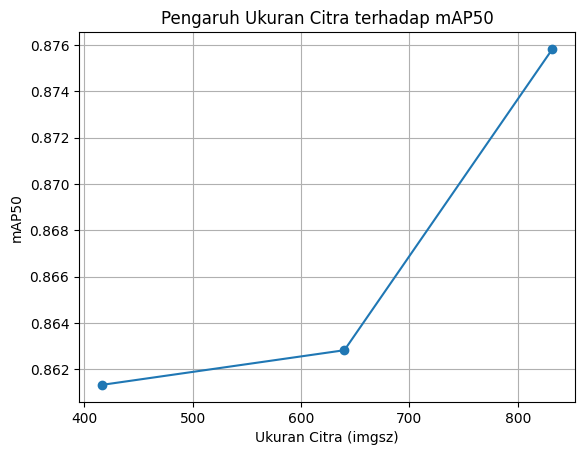

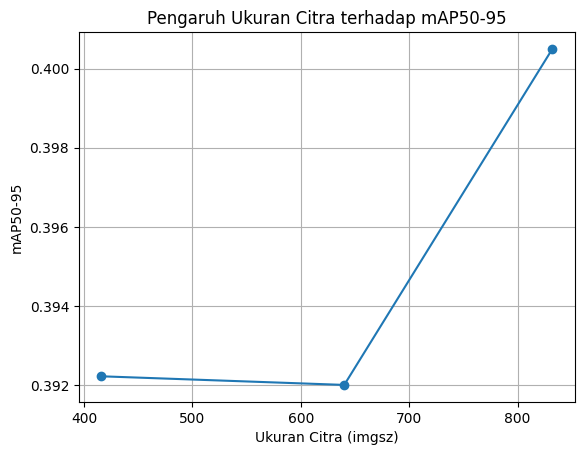

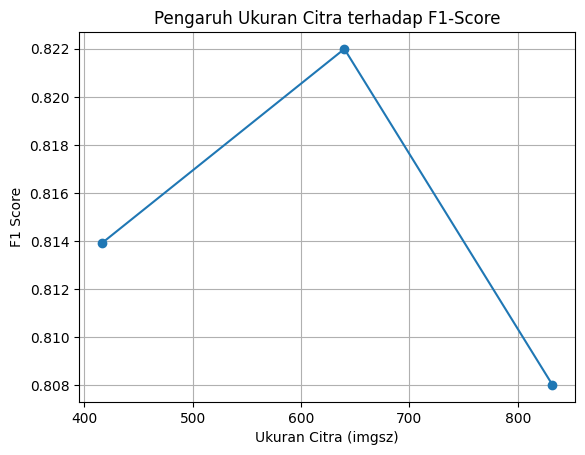

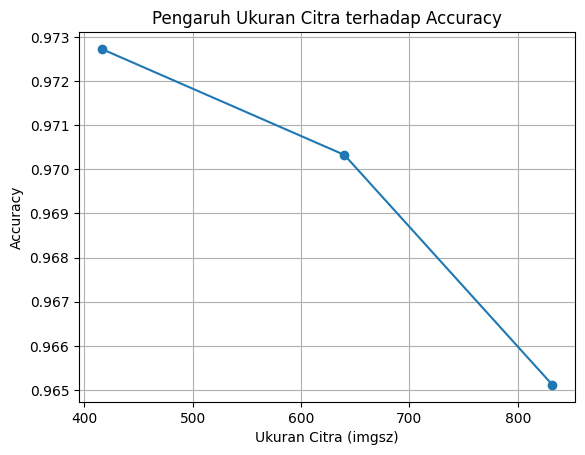

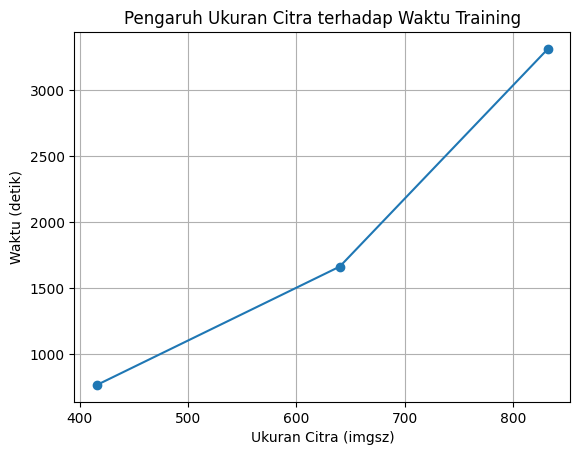


🏆 UKURAN TERBAIK (berdasarkan mAP50):
imgsz : 832
mAP50 : 0.8758
F1    : 0.8080
Time  : 3310.0 detik

📌 Catatan:
- Ukuran lebih besar → mAP cenderung naik
- Tapi waktu training juga meningkat (trade-off)


In [ ]:
# ================================
# 📦 IMPORT
# ================================
from ultralytics import YOLO
import pandas as pd
import numpy as np
import torch, random, time, os, shutil
import matplotlib.pyplot as plt

# (Optional download di Colab)
try:
    from google.colab import files
    IN_COLAB = True
except:
    IN_COLAB = False

# ================================
# ⚙️ CONFIG
# ================================
MODEL_NAME = "yolo12s.pt"
DATA_YAML = "/content/data_skenario3/skenario_3/skenario_3/datasetSKENARIO3.yaml"
IMG_SIZES = [416, 640, 832]
EPOCHS = 30
SEED = 0

# Path output CSV di Drive
CSV_PATH = "/content/drive/MyDrive/SKRIPSI_YOLO/Size_Test_Skenario3_YOLO12s.csv"

# Folder runs YOLO (default)
RUNS_DIR = "/content/runs/detect"

# ================================
# 🔁 SET SEED (BIAR FAIR)
# ================================
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# ================================
# 🚀 TRAIN + EVAL LOOP
# ================================
results = []

for imgsz in IMG_SIZES:
    print("\n" + "="*60)
    print(f"🚀 TRAIN imgsz = {imgsz}")
    print("="*60)

    # ⏱️ start timing
    start_time = time.time()

    model = YOLO(MODEL_NAME)

    # 🔥 TRAIN
    model.train(
        data=DATA_YAML,
        epochs=EPOCHS,
        imgsz=imgsz,
        batch=16,
        amp=True,
        seed=SEED,
        name=f"SIZE_TEST_{imgsz}"
    )

    # ⏱️ end timing
    end_time = time.time()
    train_time = end_time - start_time

    # 📊 VALIDASI
    metrics = model.val(data=DATA_YAML)

    # Ambil metrik
    P = float(metrics.box.p.mean())
    R = float(metrics.box.r.mean())
    mAP50 = float(metrics.box.map50)
    mAP5095 = float(metrics.box.map)

    # F1
    F1 = float(2 * (P * R) / (P + R + 1e-6))

    # Accuracy dari confusion matrix
    cm = metrics.confusion_matrix.matrix
    if cm.shape[0] > 2:
        cm = cm[:2, :2]

    TP, TN, FP, FN = cm[1,1], cm[0,0], cm[0,1], cm[1,0]
    ACC = float((TP + TN) / (TP + TN + FP + FN + 1e-6))

    # Simpan hasil
    results.append({
        "imgsz": imgsz,
        "precision": P,
        "recall": R,
        "mAP50": mAP50,
        "mAP50-95": mAP5095,
        "accuracy": ACC,
        "f1_score": F1,
        "train_time_sec": train_time
    })

# ================================
# 💾 SIMPAN CSV KE DRIVE
# ================================
df = pd.DataFrame(results)
os.makedirs(os.path.dirname(CSV_PATH), exist_ok=True)
df.to_csv(CSV_PATH, index=False)

print("\n📊 HASIL UJI UKURAN")
display(df)
print(f"✅ CSV disimpan di: {CSV_PATH}")

# ================================
# 📦 ZIP HASIL RUNS (SEMUA SIZE_TEST)
# ================================
TEMP_DIR = "/content/temp_size_test"
ZIP_PATH = "/content/Size_Test_Skenario3_YOLO12s.zip"

# Bersihkan temp dir
if os.path.exists(TEMP_DIR):
    shutil.rmtree(TEMP_DIR)
os.makedirs(TEMP_DIR, exist_ok=True)

# Copy semua folder hasil yang mengandung "SIZE_TEST_"
if os.path.exists(RUNS_DIR):
    for folder in os.listdir(RUNS_DIR):
        if "SIZE_TEST_" in folder:
            src = os.path.join(RUNS_DIR, folder)
            dst = os.path.join(TEMP_DIR, folder)
            try:
                shutil.copytree(src, dst)
            except Exception as e:
                print(f"⚠️ Skip {folder}: {e}")

# Buat zip
shutil.make_archive(ZIP_PATH.replace(".zip",""), 'zip', TEMP_DIR)
print(f"📦 ZIP siap: {ZIP_PATH}")

# Download jika di Colab
if IN_COLAB:
    try:
        files.download(ZIP_PATH)
    except Exception as e:
        print("⚠️ Gagal auto-download, download manual dari Files panel.")

# ================================
# 📈 GRAFIK (SEMUA METRIK)
# ================================

# Helper untuk plot garis
def plot_line(x, y, title, xlabel, ylabel):
    plt.figure()
    plt.plot(x, y, marker='o')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(True)
    plt.show()

# mAP50
plot_line(df["imgsz"], df["mAP50"],
          "Pengaruh Ukuran Citra terhadap mAP50",
          "Ukuran Citra (imgsz)", "mAP50")

# mAP50-95
plot_line(df["imgsz"], df["mAP50-95"],
          "Pengaruh Ukuran Citra terhadap mAP50-95",
          "Ukuran Citra (imgsz)", "mAP50-95")

# F1
plot_line(df["imgsz"], df["f1_score"],
          "Pengaruh Ukuran Citra terhadap F1-Score",
          "Ukuran Citra (imgsz)", "F1 Score")

# Accuracy
plot_line(df["imgsz"], df["accuracy"],
          "Pengaruh Ukuran Citra terhadap Accuracy",
          "Ukuran Citra (imgsz)", "Accuracy")

# Training Time
plot_line(df["imgsz"], df["train_time_sec"],
          "Pengaruh Ukuran Citra terhadap Waktu Training",
          "Ukuran Citra (imgsz)", "Waktu (detik)")

# ================================
# 🧠 AUTO INTERPRETASI (SINGKAT)
# ================================
best_idx = df["mAP50"].idxmax()
best_row = df.loc[best_idx]

print("\n🏆 UKURAN TERBAIK (berdasarkan mAP50):")
print(f"imgsz : {int(best_row['imgsz'])}")
print(f"mAP50 : {best_row['mAP50']:.4f}")
print(f"F1    : {best_row['f1_score']:.4f}")
print(f"Time  : {best_row['train_time_sec']:.1f} detik")

print("\n📌 Catatan:")
print("- Ukuran lebih besar → mAP cenderung naik")
print("- Tapi waktu training juga meningkat (trade-off)")

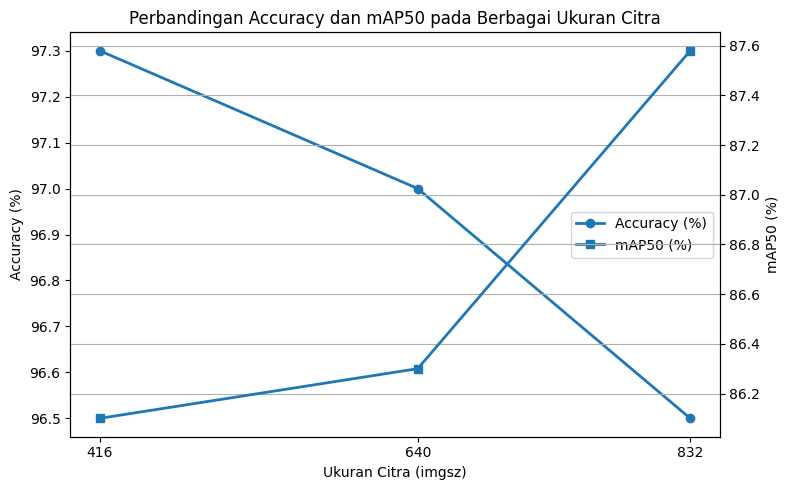

In [ ]:
import matplotlib.pyplot as plt

imgsz = [416, 640, 832]

accuracy = [97.3, 97.0, 96.5]
map50 = [86.10, 86.30, 87.58]

fig, ax1 = plt.subplots(figsize=(8,5))

# Accuracy
ax1.plot(imgsz, accuracy, marker='o', linewidth=2, label='Accuracy (%)')
ax1.set_xlabel('Ukuran Citra (imgsz)')
ax1.set_ylabel('Accuracy (%)')
ax1.set_xticks(imgsz)

# mAP50
ax2 = ax1.twinx()
ax2.plot(imgsz, map50, marker='s', linewidth=2, label='mAP50 (%)')
ax2.set_ylabel('mAP50 (%)')

# Gabung legenda
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2,
           labels1 + labels2,
           loc='center right')

plt.title('Perbandingan Accuracy dan mAP50 pada Berbagai Ukuran Citra')
plt.grid(True)
plt.tight_layout()
plt.show()